# 00 — Data audit

Before fitting anything, establish what the data can support. Five questions, from
[research/README.md](../README.md#step-0-data-audit-shared-by-both-proposals):

1. How many weeks of history have stream coverage, and where are the gaps?
2. Which races exist, at what distances?
3. How many near-maximal best efforts exist per distance?
4. How noisy is weekly efficiency factor (EF) week to week?
5. What does Garmin add?

Data: the app's `/api/research/dataset` (derived metrics) and the local snapshot
database (raw best efforts), taken with `scripts/research-snapshot.ps1`.

In [1]:
import sys
sys.path.insert(0, "..")

import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from goalsplit_research import data
from goalsplit_research.performance import vdot, robust_noise_sd

pd.set_option("display.width", 140)
plt.rcParams.update({"figure.figsize": (11, 3.2), "axes.spines.top": False, "axes.spines.right": False})

ds = data.fetch_dataset()
acts = data.activities_frame(ds)
daily = data.daily_frame(ds)
runs = acts[acts["type"] == "Run"].copy()
print(f"Dataset generated {ds['generatedAt']} · metrics v{ds['metricsVersion']}")
print(f"{len(acts)} activities ({len(runs)} runs) · {daily.index.min():%d %b %Y} → {daily.index.max():%d %b %Y}")
print("Physiology:", {k: ds["physiology"][k] for k in ["hrMax", "hrRest", "hrRestSource", "sex", "zoneModel"]})

Dataset generated 2026-10-18T11:25:45.020Z · metrics v1
219 activities (216 runs) · 06 Feb 2024 → 18 Oct 2026
Physiology: {'hrMax': 214, 'hrRest': 46, 'hrRestSource': 'garmin', 'sex': None, 'zoneModel': 'karvonen'}


## 1. Coverage and gaps

141 calendar weeks; 99 with at least one run (70%)
Runs with streams: 100%

Breaks of 2+ weeks with no running:
     start  weeks
2024-03-04      3
2024-07-15      3
2024-08-12      6
2024-10-14      6
2024-12-02      4
2025-01-27      2
2025-04-14      2
2025-11-24      4
2026-03-09      2


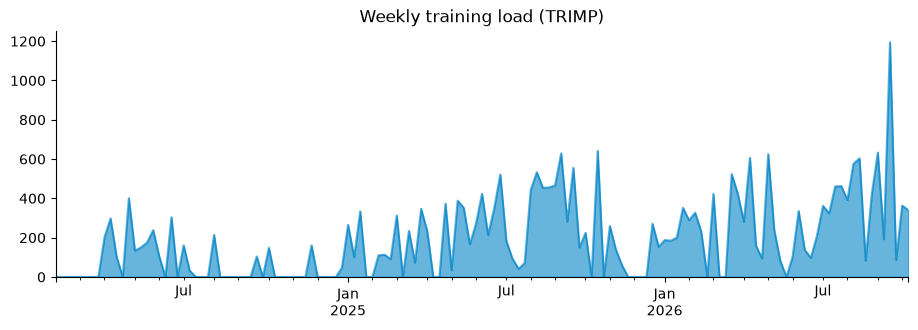

In [2]:
weekly = daily["load"].resample("W-MON", label="left", closed="left").sum().to_frame("trimp")
weekly["runs"] = runs.groupby("week").size().reindex(weekly.index, fill_value=0)
weekly["streams"] = runs[runs["hasStreams"]].groupby("week").size().reindex(weekly.index, fill_value=0)

total_weeks = len(weekly)
active_weeks = int((weekly["runs"] > 0).sum())
print(f"{total_weeks} calendar weeks; {active_weeks} with at least one run ({active_weeks / total_weeks:.0%})")
print(f"Runs with streams: {runs['hasStreams'].mean():.0%}")

# Gaps: runs of consecutive weeks with no running at all
empty = (weekly["runs"] == 0).astype(int)
gap_id = (empty.diff() != 0).cumsum()
gaps = weekly[empty == 1].groupby(gap_id[empty == 1]).apply(lambda g: pd.Series({"start": g.index[0], "weeks": len(g)}))
print("\nBreaks of 2+ weeks with no running:")
print(gaps[gaps["weeks"] >= 2].to_string(index=False) if len(gaps) else "none")

ax = weekly["trimp"].plot(kind="area", alpha=0.6, color="#0284c7")
ax.set_title("Weekly training load (TRIMP)")
ax.set_xlabel("")
plt.show()

## 2. Races

No run is tagged as a race on Strava (workout type 1), so candidates are inferred:
an activity name that reads like an event, **or** a best effort within 3% of the
athlete's all-time best at a standard distance of 5 km or more. This list is for
review and tagging, not ground truth.

In [3]:
print("Strava workout_type counts:", acts["workoutType"].value_counts(dropna=False).to_dict())

RACE_WORDS = r"marathon|maratona|half|mezza|\b\d+\s?k\b|race|gara|parkrun|backyard|trail|ultra|corsa|cross|\bcup\b|memorial"
named = runs[runs["name"].str.contains(RACE_WORDS, case=False, regex=True)]

be = data.best_efforts()
long_be = be[be["distance_m"] >= 5000].copy()
long_be["best"] = long_be.groupby("effort")["elapsed_s"].transform("min")
near_best = long_be[long_be["elapsed_s"] <= long_be["best"] * 1.03]

candidates = runs[runs["id"].isin(set(named["id"]) | set(near_best["activity_id"]))].copy()
candidates["why"] = np.where(candidates["id"].isin(named["id"]), "name", "")
candidates.loc[candidates["id"].isin(near_best["activity_id"]), "why"] += np.where(
    candidates.loc[candidates["id"].isin(near_best["activity_id"]), "why"] == "", "near-best effort", " + near-best effort")
candidates["km"] = (candidates["distanceM"] / 1000).round(1)
candidates["time"] = pd.to_timedelta(candidates["movingTimeS"], unit="s").astype(str).str[-8:]
print(f"\n{len(candidates)} race candidates:")
print(candidates[["localDate", "name", "km", "time", "avgHr", "runClass", "why"]].to_string(index=False))

Strava workout_type counts: {nan: 158, 0.0: 61}



27 race candidates:
 localDate                              name    km     time      avgHr runClass                     why
2024-04-20                       Morning Run   5.0 00:20:08 189.987583  workout        near-best effort
2024-05-01                      4k & 2x 800m   5.8 00:25:09 185.596817  workout                    name
2024-08-10          Gaelforce Bray Trail Run   9.9 01:03:18 198.784396  workout                    name
2025-04-29                           4x 1.5k   6.0 00:25:09 193.744171  workout                    name
2025-06-04        7k Easy Run + 5x 1k @ 4:15  12.3 01:09:41 155.169598  workout                    name
2025-06-18                 9k Easy, 5k Tempo  14.0 01:15:54 153.809786  workout                    name
2025-06-21                     Pisa walls 7k   7.6 00:33:39 189.540110  workout                    name
2025-08-16                      Post-Parkrun  12.5 01:03:17 177.994461  workout                    name
2025-09-02                   15k @ Race Pac

## 3. Best efforts and the performance index

Strava records best efforts at standard distances inside *every* run, so most are
segments of easy runs, not maximal efforts. For each distance: how many exist, and
how many are within 5% of the athlete's best at that distance (a rough
"near-maximal" filter).

In [4]:
be["best"] = be.groupby("effort")["elapsed_s"].transform("min")
be["near_max"] = be["elapsed_s"] <= be["best"] * 1.05
summary = be.groupby("effort").agg(
    efforts=("elapsed_s", "size"),
    near_max=("near_max", "sum"),
    best_s=("best", "first"),
    distance_m=("distance_m", "first"),
).sort_values("distance_m")
summary["best"] = pd.to_timedelta(summary["best_s"], unit="s").astype(str).str[-8:]
summary["best_vdot"] = [round(vdot(d, t), 1) for d, t in zip(summary["distance_m"], summary["best_s"])]
print(summary[["efforts", "near_max", "best", "best_vdot"]].to_string())

               efforts  near_max      best  best_vdot
effort                                               
400m               210         1  00:01:05       62.5
1/2 mile           210        14  00:02:52       47.5
1K                 210        10  00:03:40       46.8
1 mile             210        12  00:06:12       46.7
2 mile             205         9  00:12:40       49.1
5K                 197         7  00:20:06       49.5
10K                118         3  00:41:27       49.8
15K                 47         1  01:03:14       50.3
10 mile             43         1  01:08:05       50.4
20K                 24         1  01:25:28       50.7
Half-Marathon       22         2  01:30:47       50.5
30K                  6         2  02:24:45       45.4
Marathon             4         1  03:32:30       43.9
50k                  3         3  07:12:21       22.3


C:\ProjectFiles\GoalSplit\research\.venv\Lib\site-packages\pandas\plotting\_matplotlib\core.py:999: UserWarning: This axis already has a converter set and is updating to a potentially incompatible converter
  return ax.plot(*args, **kwds)


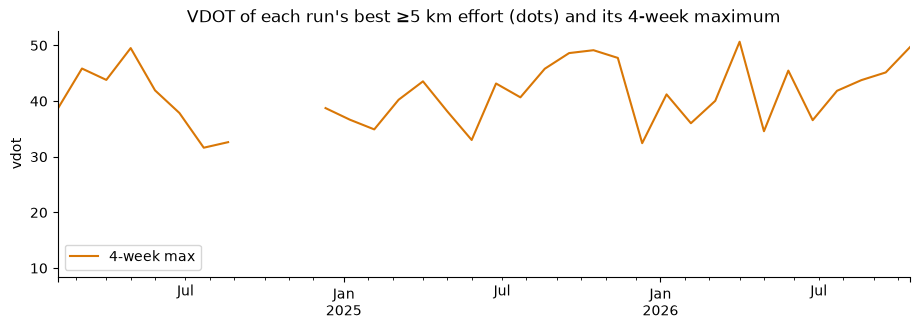

4-week blocks with at least one ≥5 km effort: 34


In [5]:
# A per-run performance index: VDOT of each run's best effort at 5 km or more.
# Its upper envelope over time approximates race fitness; the bulk is submaximal.
pi = long_be.assign(vdot=[vdot(d, t) for d, t in zip(long_be["distance_m"], long_be["elapsed_s"])])
per_run = pi.groupby(["activity_id", "local_date"])["vdot"].max().reset_index()
ax = per_run.plot.scatter(x="local_date", y="vdot", s=10, alpha=0.5, color="#0284c7")
per_run.set_index("local_date")["vdot"].resample("4W").max().plot(ax=ax, color="#d97706", label="4-week max")
ax.set_title("VDOT of each run's best ≥5 km effort (dots) and its 4-week maximum")
ax.set_xlabel(""); ax.legend()
plt.show()
weeks_with_index = per_run.set_index("local_date")["vdot"].resample("4W").max().notna().sum()
print(f"4-week blocks with at least one ≥5 km effort: {weeks_with_index}")

## 4. Run classification and weekly efficiency factor

Proposal 1's dense performance measure is weekly median EF of *aerobic* runs (easy,
recovery, long). First, how many runs that leaves — the app classifies a run as a
workout when ≥50% of its HR time is in Z3+ or ≥15% in Z4+.

Run classes: {'workout': 104, 'easy': 53, 'long': 47, 'unknown': 8, 'recovery': 4}
Zone floors (bpm): {'Z1 Recovery': 46, 'Z2 Aerobic': 147, 'Z3 Tempo': 164, 'Z4 Threshold': 180, 'Z5 Max': 197}


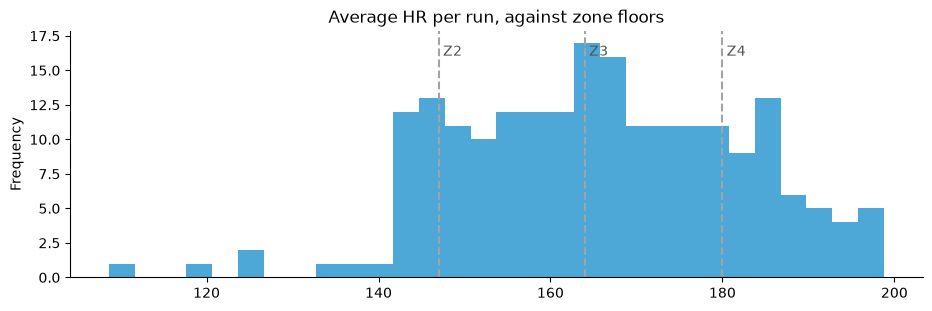

Median average HR of runs classed as workouts: 175 bpm


In [6]:
print("Run classes:", runs["runClass"].value_counts().to_dict())
z = ds["physiology"]["zones"]
print("Zone floors (bpm):", {b["label"]: b["minBpm"] for b in z})

ax = runs["avgHr"].plot(kind="hist", bins=30, color="#0284c7", alpha=0.7)
for b in z[1:4]:
    ax.axvline(b["minBpm"], color="#a3a3a3", linestyle="--")
    ax.text(b["minBpm"] + 0.5, ax.get_ylim()[1] * 0.9, b["label"].split()[0], color="#525252")
ax.set_title("Average HR per run, against zone floors")
plt.show()

workout_avg = runs.loc[runs["runClass"] == "workout", "avgHr"].median()
print(f"Median average HR of runs classed as workouts: {workout_avg:.0f} bpm")

                        series  weeks with data  median EF  noise SD (week-to-week)  signal SD (8-wk trend)  signal / noise  lag-1 autocorr
aerobic runs (current classes)               62      1.138                    0.067                   0.034            0.51            0.27
                      all runs               95      1.143                    0.061                   0.046            0.76            0.52


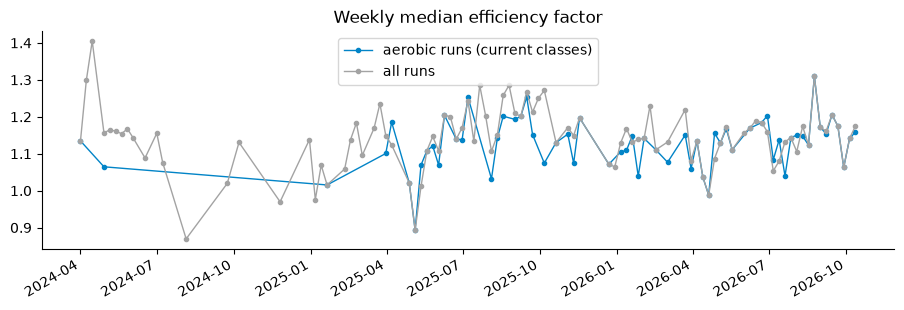

In [7]:
def weekly_ef(frame: pd.DataFrame) -> pd.Series:
    return frame.dropna(subset=["ef"]).groupby("week")["ef"].median()

aerobic = runs[runs["runClass"].isin(["easy", "recovery", "long"])]
variants = {
    "aerobic runs (current classes)": weekly_ef(aerobic),
    "all runs": weekly_ef(runs),
}
rows = []
for label, s in variants.items():
    s = s.reindex(weekly.index)
    noise = robust_noise_sd(s.dropna().values)
    signal = s.rolling(8, center=True, min_periods=4).median().std()
    rows.append({
        "series": label,
        "weeks with data": int(s.notna().sum()),
        "median EF": round(s.median(), 3),
        "noise SD (week-to-week)": round(noise, 3),
        "signal SD (8-wk trend)": round(signal, 3),
        "signal / noise": round(signal / noise, 2),
        "lag-1 autocorr": round(s.autocorr(1), 2),
    })
print(pd.DataFrame(rows).to_string(index=False))

fig, ax = plt.subplots()
for (label, s), color in zip(variants.items(), ["#0284c7", "#a3a3a3"]):
    s.plot(ax=ax, marker="o", ms=3, lw=1, color=color, label=label)
ax.set_title("Weekly median efficiency factor")
ax.set_xlabel(""); ax.legend()
plt.show()

## 5. Garmin

In [8]:
g = data.garmin_days()
cols = ["resting_heart_rate", "sleep_duration_hours", "avg_stress_level", "body_battery_high", "hrv_last_night_avg"]
print(f"{len(g)} days, {g['day'].min():%d %b %Y} → {g['day'].max():%d %b %Y}" if len(g) else "no Garmin days")
print(g[cols].notna().sum().to_string())

13 days, 05 Oct 2026 → 18 Oct 2026
resting_heart_rate      13
sleep_duration_hours     8
avg_stress_level        13
body_battery_high       13
hrv_last_night_avg       0


## Conclusions

**1. Coverage is good.** 141 calendar weeks, 99 with running, streams on every run.
Nine breaks of 2+ weeks (two of 6 weeks in 2024). The fitness–fatigue model treats
them as zero-load days, which is correct, but they get flagged in sensitivity checks.

**2. Races must be tagged by hand.** No run carries Strava's race tag. Of 27
inferred candidates, about 12 are genuine events (Gaelforce Bray, Pisa 10k ×2,
Venice Marathon, Lucca Parkrun, Empoli and Cascina 18k, Firenze Half, Tuscany
Crossing, AIRC 10k, Backyard Cervia); the rest are workouts matched by name (e.g.
"4k & 2x 800m"). Too few races to *fit* a model on, but enough to *validate* one.

**3. Best efforts are consistent up to the half marathon.** VDOT is about 49.5–50.7
at every distance from 5 km to the half, then 45.4 at 30 km and 43.9 at the
marathon: a clear endurance falloff past the half (evidence for Proposal 2). VDOT is
meaningless for trail ultras (the 50 km figure of 22.3), so those are excluded from
any performance index.

**4. Weekly median EF is mostly noise.** Signal-to-noise is 0.51 using aerobic runs
only (62 weeks) and 0.76 using all runs (95 weeks): week-to-week scatter is larger
than the trend. Classification isn't the problem. Race HR (198 bpm average over
10 km) supports HRmax 214, and runs classed as workouts genuinely average 175 bpm.
This athlete simply runs a lot of moderate-to-hard sessions.

**5. Garmin adds nothing yet:** 13 days, and no HRV on a Forerunner 55.

### Decisions for Proposal 1

- **Model runs, not weeks.** Fit the fitness–fatigue model with *each run* as an
  observation (216 runs instead of about 60 noisy weekly medians). Intensity (average
  %HRR), duration and terrain are covariates, so easy and hard runs are compared
  like with like instead of half the data being discarded.
- **Races are the out-of-sample check.** After tagging, the model's predicted
  performance on race days is compared with race VDOT (road races up to the
  marathon only).
- **Garmin is out of scope** for this question.